<a href="https://colab.research.google.com/github/Penn2001/MSSP-607/blob/main/WeeklyModules/Week08/Participation_Activity_Week8_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [98]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [99]:
#Connect to my GitHub repository using the file distributed in class
%run '/content/drive/MyDrive/Google_connection.py'

Changed directoGit_HUBry to: /content/MSSP-607/MSSP-607/MSSP-607/MSSP-607/MSSP-607


<Figure size 1000x600 with 0 Axes>

In [100]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import datetime as dt
import plotly.express as px

%matplotlib inline
pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.0f' % x) #set precision for results and visualizations

plt.rc('figure', figsize=(10, 6)) #size of the figure
np.set_printoptions(precision=4, suppress=True) #precision set

In [101]:
#Load the Interent Sales CSV and parse the date series to change the datatype to datetime and assign the ID series as the index.
internet_sales = pd.read_csv('/content/MSSP-607/data/InternetSales.csv', parse_dates=['BirthDate','DateFirstPurchase','OrderDate','DueDate','ShipDate'],
                   low_memory=False,index_col='ID', encoding='latin-1')
internet_sales.head(5)

,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,LastName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
ID,,,,,,,,,,,,,,,,,,,,,
0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1912,1912,3400,272,85,NaN,NaN,2011-01-19,2011-01-31,2011-01-26
1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1266,1266,2320,186,58,NaN,NaN,2013-01-18,2013-01-30,2013-01-25
2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,8,8,22,2,1,NaN,NaN,2013-01-18,2013-01-30,2013-01-25
3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1482,1482,2384,191,60,NaN,NaN,2013-05-03,2013-05-15,2013-05-10
4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,11,11,29,2,1,NaN,NaN,2013-05-03,2013-05-15,2013-05-10


In [102]:
internet_sales['OrderDate'] #Notice using the parse option reads the date objects into the data frame as datetime data types.

,OrderDate
ID,
0,2011-01-19
1,2013-01-18
2,2013-01-18
3,2013-05-03
4,2013-05-03
...,...
60393,2013-07-17
60394,2013-07-17
60395,2011-08-13


In [103]:
#Return a data frame for the graph by year of the order.
#Here, the year series is used to select the year component from the date and set the index to the year.
#I can choose the years because the OrderDate series is of type datetime date type, not an object.
internet_sales.groupby(internet_sales['OrderDate'].dt.year,as_index=True).agg({'SalesAmount':'sum'})


,SalesAmount
OrderDate,
2010,43421
2011,7075526
2012,5842485
2013,16351550
2014,45695


In [104]:
#Add date parts to the dataframe for future use in the analysis; select subcomponents of the OrderDate.
internet_sales = internet_sales.assign(orderyear = internet_sales['OrderDate'].dt.year)
internet_sales = internet_sales.assign(orderquarter = internet_sales['OrderDate'].dt.quarter)
internet_sales = internet_sales.assign(ordermonth = internet_sales['OrderDate'].dt.month)
internet_sales = internet_sales.assign(orderday = internet_sales['OrderDate'].dt.day)
internet_sales = internet_sales.assign(daynumber = internet_sales['orderyear']+internet_sales['ordermonth']+internet_sales['orderday'])

#Determine quarterly sales.  Notice 2010 and 2014 are incomplete years.
internet_sales.groupby(['orderyear','orderquarter']).agg({'SalesAmount':'sum'},as_index=True )

SalesAmount
orderyear orderquarter             
2010      4                   43421
2011      1                 1421357
          2                 1801595
          3                 1814388
          4                 2038185
2012      1                 1375841
          2                 1314374
          3                 1454653
          4                 1697617
2013      1                 2678946
          2                 3973793
          3                 4370237
          4                 5328574
2014      1                   45695

In [105]:
#Determine the number of rows and columns of the dataframe; I added date components to the original data frame.
internet_sales.shape

(60398, 64)

In [106]:
#Drop outliers in 2010 and 2014 to have valid sales: December 2010 and January 2014 were short years.
#The inplace=True option changes the dataframe explicitly.
internet_sales.query('"2010-12-31" < OrderDate' , inplace=True)
internet_sales.query('OrderDate < "2013-12-29"', inplace=True)
internet_sales.groupby(['orderyear','orderquarter']).agg({'SalesAmount':'sum'},as_index=True )

SalesAmount
orderyear orderquarter             
2011      1                 1421357
          2                 1801595
          3                 1814388
          4                 2038185
2012      1                 1375841
          2                 1314374
          3                 1454653
          4                 1697617
2013      1                 2678946
          2                 3973793
          3                 4370237
          4                 5323428

In [107]:
internet_sales.shape #Notice the decrease in rows.

(58175, 64)

In [108]:
#Return a dataframe of yearly sales.  Notice the as_index=False
#determines that the groupby series is not the index.
#Many models require datetime indexes.
yearly_sales = internet_sales.groupby(['orderyear'], as_index=False).agg({'SalesAmount':'sum'})
yearly_sales

,orderyear,SalesAmount
0,2011,7075526
1,2012,5842485
2,2013,16346404


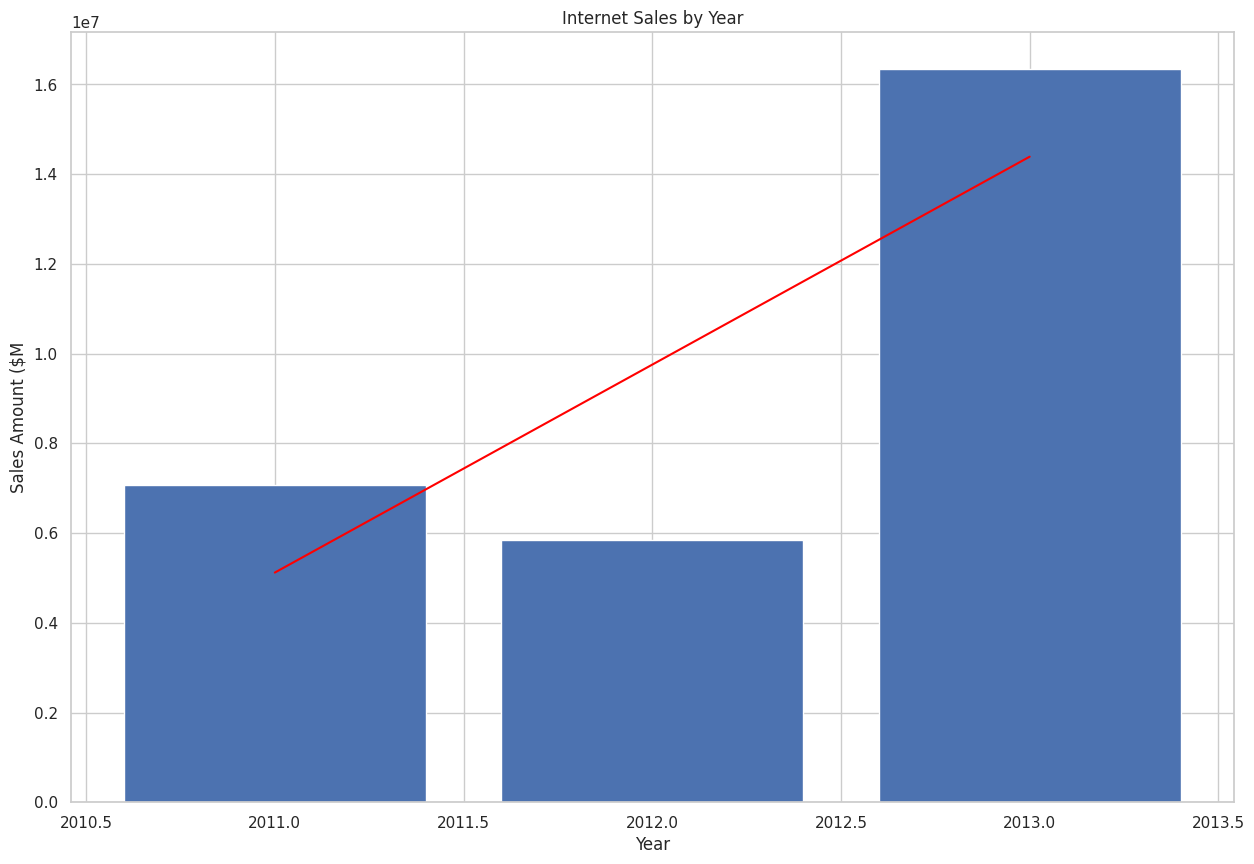

In [109]:
#As we discussed in classs, there are several ways to determine a plotline for the assignment.
#The version below uses the Numpy polyplot model to fit the line
#See https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html.
#The methods fits a a line that minimizes the squared error of the data points.
#The deg specifies the degree of fit to the data

fig = plt.figure(figsize = (15, 10))
ax1 = plt.bar(yearly_sales['orderyear'], yearly_sales['SalesAmount'])

z = np.polyfit(yearly_sales['orderyear'], yearly_sales['SalesAmount'], deg=1)
p = np.poly1d(z)
plt.plot(yearly_sales['orderyear'], p(yearly_sales['orderyear']), color='red')

plt.xlabel("Year")
plt.ylabel("Sales Amount ($M")
plt.title("Internet Sales by Year")

plt.show()

In [110]:
#Alternatively, you can use the plot line over the Internet Sales scatter plot discussed in class.
#As I mentioned, you could plot a line over the yearly scatter plot discussed in class.
#I modified slightely the code above to the dataframe defined above.

#See https://plotly.com/python/plotly-express/

#Create a dateframe where the orderdate is the index giving me daily sales
daily_sales = internet_sales.groupby(['OrderDate'], as_index=True).agg({'SalesAmount':'sum'})
daily_sales

,SalesAmount
OrderDate,
2011-01-01,7157
2011-01-02,15012
2011-01-03,14313
2011-01-04,7856
2011-01-05,7856
...,...
2013-12-24,69534
2013-12-25,58081
2013-12-26,78907


In [111]:
import plotly.express as px

#Ordinary Least Squares regression (a straight-line fit).
#"lowess" → Locally Weighted Scatterplot Smoothing (a curved, non-parametric smooth fit)

trend_lines = ["ols", "lowess"]
x = daily_sales.index
y = daily_sales["SalesAmount"]


In [112]:
fig1 = px.scatter(daily_sales, x, y, trendline = "ols") # use ordinary least squares formula.
fig1.show()

##Adding a forecast; you can add a forecast to daily sales as well.

In [113]:
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [114]:
df = internet_sales.groupby(['orderyear'], as_index=False).agg({'SalesAmount':'sum'})
df

,orderyear,SalesAmount
0,2011,7075526
1,2012,5842485
2,2013,16346404


In [115]:
years = np.array(df['orderyear'])
sales = np.array(df['SalesAmount'])

#In NumPy, the reshape method is used to change the shape of an array without changing its data.
#This method allows you to modify the dimensions of the array, provided that the total number of
#elements in the new shape is equal to the total number of elements in the original array.
#The -1 is a placeholder that allows NumPy to automatically determine the size of that dimension based on the length of the original array.

X=years.reshape(-1,1)
y = sales.reshape(-1,1)

In [116]:
model = LinearRegression()
model.fit(X, y)

LinearRegression()

In [117]:
future_years = np.arange(2014, 2020).reshape(-1, 1)
future_years

array([[2014],
       [2015],
       [2016],
       [2017],
       [2018],
       [2019]])

In [118]:
forecast = model.predict(future_years)

In [119]:
forecast

array([[19025683.6857],
       [23661122.9361],
       [28296562.1866],
       [32932001.437 ],
       [37567440.6875],
       [42202879.9379]])

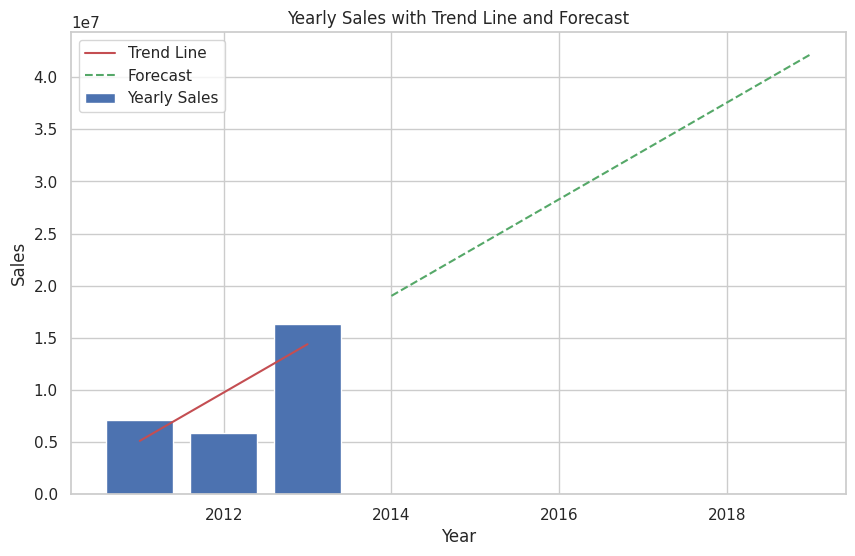

In [120]:
plt.figure(figsize=(10, 6))
sns.set(style="whitegrid")
plt.bar(years, sales, color='b', label='Yearly Sales')
plt.plot(years, model.predict(X), color='r', label='Trend Line')
plt.plot(future_years, forecast, linestyle='dashed', color='g', label='Forecast')
plt.title('Yearly Sales with Trend Line and Forecast')
plt.xlabel('Year')
plt.ylabel('Sales')
plt.legend()
plt.show()
